# 07b — The optimal interval on native gates

## Premise

07 found Δt\* under trapped-ion idle noise (Z only, linear and quadratic in time) on **Stim's
textbook circuit**, where a CNOT is one `CX` charged `p_2q` once. Selene compiles each CNOT into
one `Rzz` and four single-qubit gates (06a), and Selene's own error model cannot express the idle
noise (no duration term, 03). Neither tool alone gives native gates *and* dephasing.

This notebook combines them (`circuit_level.native_memory`): the gate sequence is read from
Selene's compiled program, rebuilt gate for gate in Stim (`selene_mirror`, verified in 06a), and
given 07's idle channel and 07's H2-ratio gate noise, charged per native gate. Everything else
is 07's: `T = 192`, the Δt grids, the idle settings, the seeds, the shots, the fit. **The only
thing that differs between the two arms is the gate decomposition.**

**Result.** On native gates Δt\* is **0–7% longer** than on the textbook circuit (mean 3.6%), in
the same direction on all 21 curves. Every conclusion of 07 stands, including the H2-ratio one. At
H2's gate ratios, decomposing the CNOT is not where the textbook model goes wrong.

| check / comparison | result | § |
| --- | --- | --- |
| X-basis memory, noiseless | 0 detection events and 0 logical flips, Selene and copy, d = 3, 5, 7 | 1 |
| X-basis copy against Selene, Selene's own noise | χ²/dof 1.02 (d = 5); 1.57 then 0.81, 0.93, 1.13 on repeats (d = 3); `p_L` within 0.9σ | 1 |
| gates off: native against textbook | same circuit: max \|z\| = 2.19 over 9 points | 2 |
| `p_2q` only: native against textbook | same circuit: max \|z\| = 1.58 over 9 points | 3 |
| **Δt\*, native / textbook** | **1.003–1.074**; linear 1.036–1.074, quadratic 1.003–1.034 | 4 |
| `p_L` at the optimum, native / textbook | 1.02–1.11 | 4 |
| charging `Rz` as well | a further +0.5% to +3.7% on Δt\* | 5 |
| at H2's estimated idle ratio | unchanged: back to back is best except linear idle at d = 3 (Δt = 2.29, +12–15%) | 6 |

## 0. Setup

07's constants, unchanged, so 07's cached textbook runs are reused point for point. Native gate
noise:

| | where | rate |
| --- | --- | --- |
| `p_1q` | `DEPOLARIZE1` on every native `Rxy` | 07's `p1` |
| `Rz` | **noiseless** by default (`RZ_NOISE = False`), see §5 | — |
| `p_2q` | `DEPOLARIZE2` on every native `Rzz` | 07's `p2` |
| `p_meas` | flip of the recorded bit | 07's `p_meas` |
| `p_init` | `X_ERROR` after every reset | 07's `p_init` |

`Rz` noiseless is an **assumption** (interpretation, not checked against Quantinuum's documentation
here): on H-series hardware `Rz` is applied in software, as a frame change. §5 measures how much
it matters.

In [1]:
import sys, pathlib, time
import multiprocessing as mp
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams['mathtext.fontset'] = 'cm'
from scipy.stats import chi2 as chi2_dist

sys.path.insert(0, str(pathlib.Path.cwd().parent / 'src'))
from qec_timing.circuit_level.stim_memory import StimMemory
from qec_timing.circuit_level.native_memory import NativeMemory
from qec_timing.circuit_level import runcache, selene_mirror as sm

pd.set_option('display.width', 200)
FIGDIR = pathlib.Path('figures')
BLUE, ORANGE, AQUA, GRAY = '#1f5aa6', '#d9822b', '#2a9d8f', '#888888'
DCOL = {3: BLUE, 5: ORANGE, 7: AQUA}

# 07's constants (H2-1E emulator noise, 2025-07-16, scaled to p2 = 5e-3)
H2 = dict(p1=1.89e-5, p2=1.05e-3, p_meas0=6e-4, p_meas1=1.39e-3, p_init=4e-5)
P2 = 5e-3
SCALE = P2 / H2['p2']
GATES = dict(p1=H2['p1'] * SCALE, p2=P2,
             p_meas=0.5 * (H2['p_meas0'] + H2['p_meas1']) * SCALE,
             p_init=H2['p_init'] * SCALE)
H2_GATES = dict(p1=H2['p1'], p2=H2['p2'], p_meas=0.5 * (H2['p_meas0'] + H2['p_meas1']),
                p_init=H2['p_init'])
T = 192
DISTANCES = (3, 5, 7)
SHOTS, SEEDS = 100_000, (1, 2)
LIN = (0.15, 0.3, 0.6)          # gamma / p2
QUAD = (0.0025, 0.01, 0.04)     # c / p2
MIXED = (0.3, 0.01)             # (gamma, c) / p2
EXP07 = '07_dephasing_interval'
EXP = '07b_native_dephasing'
RZ_NOISE = False
N_WORKERS = min(16, mp.cpu_count())
print({k: f'{v:.3g}' for k, v in GATES.items()}, f' scale x{SCALE:.2f}, {N_WORKERS} workers')

{'p1': '9e-05', 'p2': '0.005', 'p_meas': '0.00474', 'p_init': '0.00019'}  scale x4.76, 16 workers


In [2]:
# ---- 07's helpers, copied verbatim (dt_grid, rate, optimum, idle_of) ----
def dt_grid(d, n=16):
    Rs = sorted({int(round(T / x)) for x in np.geomspace(1.0, T / d, n)
                 if round(T / x) >= d}, reverse=True)
    return [(T / R, R) for R in Rs]


def rate(F, N):
    p = F / N
    s = np.sqrt(max(p * (1 - p), 1e-12) / N)
    if p >= 0.5:
        return np.nan, np.nan
    return -np.log(1 - 2 * p) / (2 * T), s / ((1 - 2 * p) * T)


def optimum(df, rel=1.3, n_boot=2000, seed=0):
    df = df[(df.pL < 0.45) & np.isfinite(df.r)].reset_index(drop=True)
    x, y, s = np.log(df.dt.values), df.r.values, df.sr.values
    i = int(np.argmin(y))
    w = np.where(y <= rel * y[i])[0]
    lo, hi = w.min(), w.max()
    while hi - lo + 1 < 5 and (lo > 0 or hi < len(y) - 1):
        lo, hi = max(lo - 1, 0), min(hi + 1, len(y) - 1)
    sl = slice(lo, hi + 1)

    def vertex(yy):
        a, b, _ = np.polyfit(x[sl], np.log(yy[sl]), 2, w=yy[sl] / s[sl])
        if a <= 0:
            return x[sl][np.argmin(yy[sl])]
        return float(np.clip(-b / (2 * a), x[sl][0], x[sl][-1]))

    rng = np.random.default_rng(seed)
    boots = [vertex(np.maximum(y + rng.normal(0, s), 1e-12)) for _ in range(n_boot)]
    q16, q84 = np.exp(np.percentile(boots, [16, 84]))
    band = df.dt.values[(y - y[i]) <= np.sqrt(s ** 2 + s[i] ** 2)]
    return dict(dt_star=float(np.exp(vertex(y))), lo=float(q16), hi=float(q84),
                lowest=float(df.dt.values[i]), band=(round(band.min(), 2), round(band.max(), 2)),
                interior=bool(0 < i < len(y) - 1))


def idle_of(key):
    fam, val = key[0], key[1]
    if fam == 'lin':
        return val * P2, 0.0
    if fam == 'quad':
        return 0.0, val * P2
    return val[0] * P2, val[1] * P2

In [3]:
# ---- one point, either arm; cached. 'textbook' uses 07's exact key, so 07's runs are reused ----
def point_params(arm, d, dt, R, gamma, c, gates, basis, shots, seed, rz_noise=RZ_NOISE):
    p = dict(code='rotated', d=d, basis=basis, dt=float(dt), rounds=int(R),
             gamma=float(gamma), c=float(c), shots=int(shots), seed=int(seed),
             **{k: float(v) for k, v in gates.items()})
    if arm == 'native':
        p.update(circuit='native: Selene-compiled gates, native_memory', rz_noise=bool(rz_noise))
    return (EXP07 if arm == 'textbook' else EXP), p


def run_point(arm, d, dt, R, gamma, c, gates, basis, shots, seed, rz_noise=RZ_NOISE):
    exp, params = point_params(arm, d, dt, R, gamma, c, gates, basis, shots, seed, rz_noise)
    hit = runcache.load(exp, params)
    if hit is None:
        # stim_memory applies Z with probability sin^2(kappa*dt/2); kappa = 2 sqrt(c)  (07)
        kw = dict(basis=basis, **gates, dephase_linear=gamma, dephase_quad=2 * np.sqrt(c))
        M = (StimMemory('rotated', d, **kw) if arm == 'textbook'
             else NativeMemory('rotated', d, rz_noise=rz_noise, **kw))
        _, _, f = M.logical_error(tau=dt, rounds=R, shots=shots, seed=seed)
        hit = dict(fails=int(f), shots=int(shots))
        runcache.save(exp, params, hit)
    return hit['fails'], hit['shots']


# A job is a hashable tuple, so duplicates across sections collapse:
# (arm, d, dt, R, gamma, c, gates as sorted items, basis, shots, seed, extra kwargs as sorted items)
def job(arm, d, dt, R, gamma, c, gates, basis='X', shots=SHOTS, seed=1, **kw):
    return (arm, d, dt, R, gamma, c, tuple(sorted(gates.items())), basis, shots, seed,
            tuple(sorted(kw.items())))


def _args(j):
    *a, kw = j
    a[6] = dict(a[6])
    return a, dict(kw)


def run_job(j):
    a, kw = _args(j)
    return run_point(*a, **kw)


def run_all(jobs):
    # Every uncached job, in parallel (fork). Selene is touched only here, serially, to extract
    # each (d, R) native gate sequence before forking; the workers only read it from the cache.
    todo = [j for j in dict.fromkeys(jobs)
            if runcache.load(*point_params(*_args(j)[0], **_args(j)[1])) is None]
    for d, R, basis in sorted({(j[1], j[3], j[7]) for j in todo if j[0] == 'native'}):
        NativeMemory('rotated', d, basis=basis).ops(R)
    todo.sort(key=lambda j: -(j[1] ** 2 * j[3] * j[8]))          # costliest first
    t0 = time.time()
    if todo:
        with mp.get_context('fork').Pool(N_WORKERS) as pool:
            list(pool.imap_unordered(run_job, todo, chunksize=1))
    print(f'{len(dict.fromkeys(jobs))} points, {len(todo)} computed [{time.time() - t0:.0f}s]')


def curve(arm, d, gamma, c, gates=GATES, basis='X', seeds=SEEDS, shots=SHOTS, grid=None, **kw):
    rows = []
    for dt, R in (grid or dt_grid(d)):
        F = N = 0
        for sd in seeds:
            f, n = run_job(job(arm, d, dt, R, gamma, c, gates, basis, shots, sd, **kw))
            F, N = F + f, N + n
        r, sr = rate(F, N)
        rows.append(dict(dt=dt, R=R, pL=F / N, F=F, N=N, r=r, sr=sr))
    return pd.DataFrame(rows)


def curve_jobs(arm, d, gamma, c, gates=GATES, basis='X', seeds=SEEDS, shots=SHOTS, grid=None, **kw):
    return [job(arm, d, dt, R, gamma, c, gates, basis, shots, sd, **kw)
            for dt, R in (grid or dt_grid(d)) for sd in seeds]


def z_diff(a, b):
    # (pL_b - pL_a) / combined binomial sigma, per row
    pa, pb = a.F / a.N, b.F / b.N
    return (pb - pa) / np.sqrt(pa * (1 - pa) / a.N + pb * (1 - pb) / b.N)

## 1. Check: the X-basis memory in Selene, and its Stim copy

`surface_memory.Geometry(basis='X')` is new: `h` on every data qubit after allocation, `h`
before the final readout, decoded on the X-checks. Two checks, as in 06a for the Z basis:

- **(a) noiseless**: zero detection events and no logical flip, in Selene and in the Stim copy,
  at d = 3, 5, 7;
- **(b) Selene's own noise** (`p_1q = 2e-3`, `p_meas = 4e-3`, with idle ops, so every native gate
  is charged): per-detector firing rates, Selene against the copy, χ² against its own distribution;
  and the logical error rate of Selene's shots against the copy's, both decoded on the copy's
  detector error model.

In [4]:
from qec_timing.circuit_level.surface_memory import Geometry

t0 = time.time()
rows = []
for d in DISTANCES:
    G = NativeMemory('rotated', d, basis='X').G
    tau, R = 2, 3
    syn, dat = G.run(tau, R, 200, seed=1)
    det = G.detectors(syn, dat)
    c = sm.to_stim(sm.native_ops(G._runner(tau, R), G.n_data + G.n_anc),
                   sm.MemoryLayout.from_geometry(G, R))
    cd, co = c.compile_detector_sampler(seed=1).sample(1000, separate_observables=True)
    rows.append({'d': d, 'detectors': det.shape[1], 'Selene events': int(det.sum()),
                 'Selene logical flips': int(G.observable(dat).sum()),
                 'copy events': int(cd.sum()), 'copy logical flips': int(co.sum())})
NOISELESS = pd.DataFrame(rows)
print(NOISELESS.to_string(index=False), f'  [{time.time() - t0:.0f}s]')
assert (NOISELESS[['Selene events', 'Selene logical flips', 'copy events', 'copy logical flips']] == 0).all().all()

 d  detectors  Selene events  Selene logical flips  copy events  copy logical flips
 3         16              0                     0            0                   0
 5         48              0                     0            0                   0
 7         96              0                     0            0                   0   [6s]


In [5]:
t0 = time.time()
rows = []
P1S, PMS, N1 = 2e-3, 4e-3, 20_000
for d, tau, R in ((3, 4, 8), (5, 4, 8)):
    G = NativeMemory('rotated', d, basis='X').G
    c = sm.to_stim(sm.native_ops(G._runner(tau, R), G.n_data + G.n_anc),
                   sm.MemoryLayout.from_geometry(G, R), p_1q=P1S, p_meas=PMS)
    syn, dat = G.run(tau, R, N1, seed=1_000_011, p_1q=P1S, p_meas=PMS)
    det_s, obs_s = G.detectors(syn, dat).astype(bool), G.observable(dat).astype(bool)
    det_c, obs_c = c.compile_detector_sampler(seed=21).sample(N1, separate_observables=True)
    a, b = det_s.mean(0), det_c.mean(0)
    z = (a - b) / np.sqrt((a * (1 - a) + b * (1 - b)) / N1)
    m = sm.matcher(c)
    fs = int(np.sum(m.decode_batch(det_s)[:, 0] != obs_s))
    fc = int(np.sum(m.decode_batch(det_c)[:, 0] != obs_c[:, 0]))
    ps, pc = fs / N1, fc / N1
    rows.append({'d': d, 'tau': tau, 'R': R, 'detectors': len(z),
                 'chi2/dof': round(float(z @ z) / len(z), 2),
                 'p (chi2)': round(float(chi2_dist.sf(z @ z, len(z))), 3),
                 'mean rate Selene': round(a.mean(), 4), 'mean rate copy': round(b.mean(), 4),
                 'pL Selene': round(ps, 4), 'pL copy': round(pc, 4),
                 'pL z': round((ps - pc) / np.sqrt((ps * (1 - ps) + pc * (1 - pc)) / N1), 2)})
SELENE_X = pd.DataFrame(rows)
print(SELENE_X.to_string(index=False), f'  [{time.time() - t0:.0f}s]')

 d  tau  R  detectors  chi2/dof  p (chi2)  mean rate Selene  mean rate copy  pL Selene  pL copy  pL z
 3    4  8         36      1.57     0.016            0.0669          0.0678     0.0698   0.0675  0.91
 5    4  8        108      1.02     0.419            0.0779          0.0779     0.0499   0.0498  0.05   [60s]


At d = 3 the first seed block gives χ²/dof = 1.57 (p = 0.016). Repeated on three fresh, non-overlapping
seed blocks (Selene seeds 10⁶ apart, 04d), with the same copy:

In [6]:
t0 = time.time()
G = NativeMemory('rotated', 3, basis='X').G
tau, R = 4, 8
c = sm.to_stim(sm.native_ops(G._runner(tau, R), G.n_data + G.n_anc),
               sm.MemoryLayout.from_geometry(G, R), p_1q=P1S, p_meas=PMS)
rows = []
for ss, cs in ((2_000_011, 22), (3_000_011, 23), (4_000_011, 24)):
    syn, dat = G.run(tau, R, N1, seed=ss, p_1q=P1S, p_meas=PMS)
    a = G.detectors(syn, dat).astype(bool).mean(0)
    b = c.compile_detector_sampler(seed=cs).sample(N1, separate_observables=True)[0].mean(0)
    z = (a - b) / np.sqrt((a * (1 - a) + b * (1 - b)) / N1)
    rows.append({'Selene seed': ss, 'copy seed': cs, 'chi2/dof': round(float(z @ z) / len(z), 2),
                 'p (chi2)': round(float(chi2_dist.sf(z @ z, len(z))), 3)})
print(pd.DataFrame(rows).to_string(index=False), f'  [{time.time() - t0:.0f}s]')

 Selene seed  copy seed  chi2/dof  p (chi2)
     2000011         22      0.81     0.789
     3000011         23      0.93     0.589
     4000011         24      1.13     0.277   [42s]


## 2. Check: apart from the gates, the two arms are the same circuit

With **gate noise off** (`p1 = p2 = 0`) and everything else on (07's mixed idle noise, `p_meas`,
`p_init`), the native and textbook circuits apply the same channels at the same places: the idle
channel on every data qubit at the start of each round, flips after resets, flips on the
records. Their `p_L` must then agree within statistics. This is what makes §4's comparison a
comparison of gates and nothing else. d = 3, 5, 7, at three intervals each, 2 × 100,000 shots.

In [7]:
NOGATE = dict(p1=0.0, p2=0.0, p_meas=GATES['p_meas'], p_init=GATES['p_init'])
ONLY_P2 = dict(p1=0.0, p2=P2, p_meas=0.0, p_init=0.0)
gm, cm = idle_of(('mixed', MIXED))


def check_grid(d):
    g = dt_grid(d)
    return [g[0], g[len(g) // 2], g[-1]]


jobs = []
for gates in (NOGATE, ONLY_P2):
    for d in DISTANCES:
        for arm in ('textbook', 'native'):
            jobs += curve_jobs(arm, d, gm, cm, gates=gates, grid=check_grid(d))
run_all(jobs)


def same_circuit_table(gates):
    rows = []
    for d in DISTANCES:
        a = curve('textbook', d, gm, cm, gates=gates, grid=check_grid(d))
        b = curve('native', d, gm, cm, gates=gates, grid=check_grid(d))
        for i in range(len(a)):
            rows.append({'d': d, 'dt': round(a.dt[i], 2), 'R': a.R[i], 'pL textbook': round(a.pL[i], 4),
                         'pL native': round(b.pL[i], 4), 'z': round(z_diff(a, b)[i], 2)})
    return pd.DataFrame(rows)


SAME = same_circuit_table(NOGATE)
print(SAME.to_string(index=False))
print(f'\nmax |z| = {SAME.z.abs().max():.2f} over {len(SAME)} points; '
      f'chi2/dof = {(SAME.z ** 2).mean():.2f}')

72 points, 0 computed [0s]
 d    dt   R  pL textbook  pL native     z
 3  1.00 192       0.0270     0.0261 -1.72
 3  9.14  21       0.1370     0.1358 -1.10
 3 64.00   3       0.4954     0.4950 -0.23
 5  1.00 192       0.0012     0.0014  1.65
 5  7.11  27       0.0371     0.0366 -0.94
 5 38.40   5       0.4543     0.4537 -0.37
 7  1.00 192       0.0001     0.0001  0.21
 7  5.82  33       0.0063     0.0060 -1.21
 7 27.43   7       0.3430     0.3397 -2.19

max |z| = 2.19 over 9 points; chi2/dof = 1.59


## 3. Why the two-qubit noise cannot tell the arms apart

A two-qubit depolarizing channel is invariant under conjugation by any two-qubit Clifford. Inside
Selene's CNOT, `DEPOLARIZE2` on the `Rzz` can therefore be moved through the single-qubit gates
that follow it without changing it, and it lands exactly where the textbook circuit puts it,
after the `CX`. So **with `p2` alone the arms are the same noisy circuit**, and every difference
in §4 comes from `p1` on the extra native single-qubit gates. Checked: `p2` on, everything else
off.

In [8]:
ONLY2 = same_circuit_table(ONLY_P2)
print(ONLY2.to_string(index=False))
print(f'\nmax |z| = {ONLY2.z.abs().max():.2f} over {len(ONLY2)} points; '
      f'chi2/dof = {(ONLY2.z ** 2).mean():.2f}')

# where p1 lands: charged single-qubit gates per round, textbook against native
rows = []
for d in DISTANCES:
    nm = NativeMemory('rotated', d, basis='X')
    per = {}
    for R in (2, 3):
        ops = nm.ops(R)
        per[R] = {k: sum(o['op'] == k for o in ops) for k in ('Rxy', 'Rz', 'Rzz')}
    nat = {k: per[3][k] - per[2][k] for k in per[2]}
    tb = StimMemory('rotated', d, basis='X', p1=1e-3).circuit(1.0, 3)
    tb2 = StimMemory('rotated', d, basis='X', p1=1e-3).circuit(1.0, 2)
    cnt = lambda c: sum(len(i.targets_copy()) for i in c.flattened() if i.name == 'DEPOLARIZE1')
    n_data = nm.G.n_data
    rows.append({'d': d, 'textbook p1 sites / round': cnt(tb) - cnt(tb2),
                 'native Rxy / round': nat['Rxy'], 'native Rz / round': nat['Rz'],
                 'Rzz = CX / round': nat['Rzz'],
                 'native Rxy per data qubit / round': round(nat['Rxy'] / (n_data + nm.G.n_anc), 2)})
GATECOUNT = pd.DataFrame(rows)
print('\n', GATECOUNT.to_string(index=False))

 d    dt   R  pL textbook  pL native     z
 3  1.00 192       0.3399     0.3401  0.12
 3  9.14  21       0.2508     0.2498 -0.73
 3 64.00   3       0.4968     0.4971  0.17
 5  1.00 192       0.2186     0.2167 -1.39
 5  7.11  27       0.1788     0.1795  0.65
 5 38.40   5       0.4719     0.4697 -1.36
 7  1.00 192       0.1117     0.1117  0.03
 7  5.82  33       0.1090     0.1105  1.58
 7 27.43   7       0.4234     0.4229 -0.27

max |z| = 1.58 over 9 points; chi2/dof = 0.82

  d  textbook p1 sites / round  native Rxy / round  native Rz / round  Rzz = CX / round  native Rxy per data qubit / round
 3                          8                  56                 56                24                               3.29
 5                         24                 184                184                80                               3.76
 7                         48                 384                384               168                               3.96


## 4. The sweeps: textbook against native

07's three linear, three quadratic and one mixed idle setting, at d = 3, 5, 7, 16 intervals each,
2 × 100,000 shots per point, on native gates. The textbook arm is 07's own cached runs.

In [9]:
KEYS = ([('lin', l) for l in LIN] + [('quad', q) for q in QUAD] + [('mixed', MIXED)])
jobs = []
for d in DISTANCES:
    for k in KEYS:
        for arm in ('textbook', 'native'):
            jobs += curve_jobs(arm, d, *idle_of(k))
run_all(jobs)

CURVES = {(arm, k[0], k[1], d): curve(arm, d, *idle_of(k))
          for d in DISTANCES for k in KEYS for arm in ('textbook', 'native')}
OPT = {key: optimum(df) for key, df in CURVES.items()}

rows = []
for d in DISTANCES:
    for k in KEYS:
        a, b = OPT[('textbook', *k, d)], OPT[('native', *k, d)]
        ca, cb = CURVES[('textbook', *k, d)], CURVES[('native', *k, d)]
        sa, sb = (a['hi'] - a['lo']) / 2, (b['hi'] - b['lo']) / 2
        rows.append({'d': d, 'idle': f'{k[0]} {k[1]}',
                     'dt* textbook': round(a['dt_star'], 2), 'dt* native': round(b['dt_star'], 2),
                     'native / textbook': round(b['dt_star'] / a['dt_star'], 3),
                     'difference / sigma': round((b['dt_star'] - a['dt_star']) / np.hypot(sa, sb), 1),
                     'interior (both)': a['interior'] and b['interior'],
                     'min R native / textbook': round(cb.r.min() / ca.r.min(), 3)})
CMP = pd.DataFrame(rows)
print(CMP.to_string(index=False))
print(f"\nnative / textbook dt*: {CMP['native / textbook'].min():.3f} to {CMP['native / textbook'].max():.3f}, "
      f"mean {CMP['native / textbook'].mean():.3f}")

1344 points, 0 computed [0s]


 d              idle  dt* textbook  dt* native  native / textbook  difference / sigma  interior (both)  min R native / textbook
 3          lin 0.15         19.70       20.41              1.036                 2.3             True                    1.027
 3           lin 0.3          9.64       10.06              1.043                 3.5             True                    1.016
 3           lin 0.6          4.54        4.80              1.057                 3.6             True                    1.022
 3       quad 0.0025         16.65       16.80              1.009                 0.7             True                    1.039
 3         quad 0.01          8.05        8.16              1.013                 1.9             True                    1.038
 3         quad 0.04          4.05        4.14              1.021                 2.9             True                    1.035
 3 mixed (0.3, 0.01)          5.10        5.16              1.012                 1.3             True  

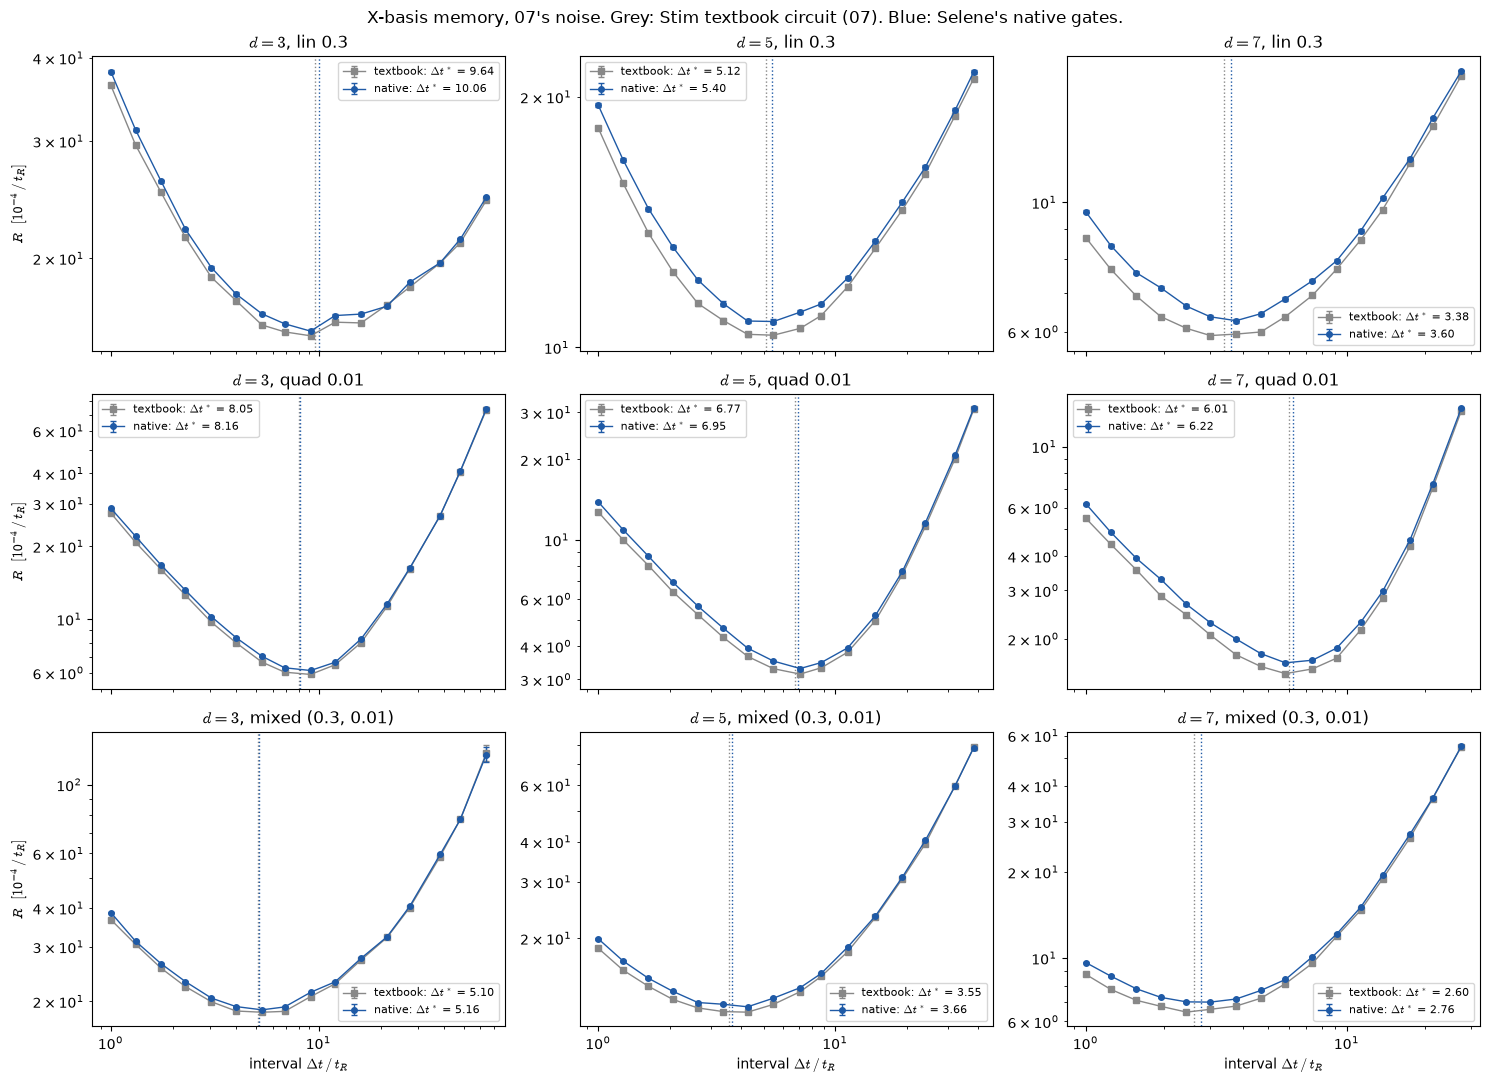

In [10]:
fig, axes = plt.subplots(3, 3, figsize=(15, 11), sharex='col')
for j, d in enumerate(DISTANCES):
    for i, k in enumerate((('lin', 0.3), ('quad', 0.01), ('mixed', MIXED))):
        ax = axes[i, j]
        for arm, col, mk in (('textbook', GRAY, 's'), ('native', BLUE, 'o')):
            df = CURVES[(arm, *k, d)]
            ax.errorbar(df.dt, df.r * 1e4, yerr=df.sr * 1e4, fmt=mk + '-', ms=4, lw=1,
                        color=col, capsize=2, label=f"{arm}: $\\Delta t^*$ = {OPT[(arm, *k, d)]['dt_star']:.2f}")
            ax.axvline(OPT[(arm, *k, d)]['dt_star'], color=col, ls=':', lw=1)
        ax.set_xscale('log'); ax.set_yscale('log')
        ax.set_title(f'$d = {d}$, {k[0]} {k[1]}')
        if j == 0:
            ax.set_ylabel(r'$R$  $[10^{-4}\,/\,t_R]$')
        if i == 2:
            ax.set_xlabel(r'interval $\Delta t\,/\,t_R$')
        ax.legend(fontsize=8)
fig.suptitle('X-basis memory, 07\'s noise. Grey: Stim textbook circuit (07). Blue: Selene\'s native gates.')
fig.tight_layout()
fig.savefig(FIGDIR / '07b_native_vs_textbook.png', dpi=130, bbox_inches='tight', facecolor='white')

## 5. Sensitivity: charging `Rz`

Everything above leaves `Rz` noiseless. Charging it `p1` like `Rxy` (Selene's own convention,
06a) on the linear 0.3 and quadratic 0.01 curves, d = 3, 5, 7.

In [11]:
jobs = []
for d in DISTANCES:
    for k in (('lin', 0.3), ('quad', 0.01)):
        jobs += curve_jobs('native', d, *idle_of(k), rz_noise=True)
run_all(jobs)
rows = []
for d in DISTANCES:
    for k in (('lin', 0.3), ('quad', 0.01)):
        o = optimum(curve('native', d, *idle_of(k), rz_noise=True))
        b = OPT[('native', *k, d)]
        rows.append({'d': d, 'idle': f'{k[0]} {k[1]}', 'dt* Rz free': round(b['dt_star'], 2),
                     'dt* Rz charged': round(o['dt_star'], 2),
                     'ratio': round(o['dt_star'] / b['dt_star'], 3)})
RZ = pd.DataFrame(rows)
print(RZ.to_string(index=False))

192 points, 0 computed [0s]


 d      idle  dt* Rz free  dt* Rz charged  ratio
 3   lin 0.3        10.06           10.43  1.037
 3 quad 0.01         8.16            8.35  1.024
 5   lin 0.3         5.40            5.59  1.035
 5 quad 0.01         6.95            7.13  1.025
 7   lin 0.3         3.60            3.72  1.034
 7 quad 0.01         6.22            6.25  1.005


## 6. At H2's estimated ratio, on native gates

07 §7b's direct check, repeated on native gates: idle error per round `q(1) = 1.1·p_2q`, all
linear or all quadratic, Δt ≤ 12. Scaled noise at d = 3, 5, 7 (2 × 100,000 shots) and real
H2-1E gate rates at d = 3, 5 (2 × 500,000). The textbook rows are 07's cached runs.

In [12]:
Q1_REL = 1.1


def h2_idle(fam, p2):
    q = Q1_REL * p2
    return (q, 0.0) if fam == 'lin' else (0.0, float(np.arcsin(np.sqrt(q)) ** 2))


CHECK = {'scaled x4.76': (GATES, (3, 5, 7), 100_000),
         'real H2': (H2_GATES, (3, 5), 500_000)}
jobs = []
for scale, (gates, ds, shots) in CHECK.items():
    for d in ds:
        grid = [(dt, R) for dt, R in dt_grid(d) if dt <= 12]
        for fam in ('lin', 'quad'):
            for arm in ('textbook', 'native'):
                jobs += curve_jobs(arm, d, *h2_idle(fam, gates['p2']), gates=gates, shots=shots, grid=grid)
run_all(jobs)

rows = []
for scale, (gates, ds, shots) in CHECK.items():
    for d in ds:
        grid = [(dt, R) for dt, R in dt_grid(d) if dt <= 12]
        for fam in ('lin', 'quad'):
            row = {'noise': scale, 'd': d, 'idle': 'all linear' if fam == 'lin' else 'all quadratic'}
            for arm in ('textbook', 'native'):
                df = curve(arm, d, *h2_idle(fam, gates['p2']), gates=gates, shots=shots, grid=grid)
                ok = df[np.isfinite(df.r)].reset_index(drop=True)
                i = int(np.argmin(ok.r.values))
                z = (ok.r[0] - ok.r[i]) / np.hypot(ok.sr[0], ok.sr[i]) if i else 0.0
                row[f'{arm}: lowest dt'] = round(ok.dt[i], 2)
                row[f'{arm}: gain over dt=1'] = f'{ok.r[0] / ok.r[i] - 1:+.1%} ({z:.1f} sigma)'
            rows.append(row)
H2N = pd.DataFrame(rows)
print(H2N.to_string(index=False))

432 points, 0 computed [0s]
       noise  d          idle  textbook: lowest dt textbook: gain over dt=1  native: lowest dt native: gain over dt=1
scaled x4.76  3    all linear                 2.29      +16.3% (10.4 sigma)               2.29     +15.2% (9.6 sigma)
scaled x4.76  3 all quadratic                 1.00        +0.0% (0.0 sigma)               1.00      +0.0% (0.0 sigma)
scaled x4.76  5    all linear                 1.27        +3.3% (3.5 sigma)               1.27      +5.1% (5.3 sigma)
scaled x4.76  5 all quadratic                 1.00        +0.0% (0.0 sigma)               1.00      +0.0% (0.0 sigma)
scaled x4.76  7    all linear                 1.00        +0.0% (0.0 sigma)               1.00      +0.0% (0.0 sigma)
scaled x4.76  7 all quadratic                 1.00        +0.0% (0.0 sigma)               1.00      +0.0% (0.0 sigma)
     real H2  3    all linear                 2.29      +10.9% (16.7 sigma)               2.29    +12.0% (18.5 sigma)
     real H2  3 all quadrati

## 7. Findings

Each finding says where it comes from: **measured here**, **repo** (a choice made in this repo's
code) or **interpretation** (my reading, not tested).

**1. Native gates lengthen Δt\* slightly, always in the same direction.** (Measured here, §4.)
Native / textbook Δt\* is 1.003–1.074 over 21 curves, mean 1.036. It is above 1 on every curve and
at least 3σ above on 10 of them (all six linear curves at d = 5 and 7, linear 0.3 and 0.6 at d = 3,
and the mixed point at d = 5 and 7). Every curve keeps its interior optimum.

**2. The two-qubit noise is identical in both arms. Only `p_1q` on the extra single-qubit gates
differs.** (Measured here, §2–3, plus an argument.) A two-qubit depolarizing channel is unchanged by
any two-qubit Clifford, so `DEPOLARIZE2` on the native `Rzz` equals `DEPOLARIZE2` after the `CX`.
With `p_2q` alone the arms agree (max |z| = 1.58), and with gates off they agree too (2.19). What is
left is `p_1q` on the native `Rxy`: 56, 184 and 384 per round at d = 3, 5, 7, against 8, 24 and 48
charged `H` in the textbook circuit. H2's `p_1q` is 55× below its `p_2q`, so those extra gates add
only a few percent to the cost of a round.

**3. The size of the shift fits the closed form of 07.** (Interpretation, consistent with the
numbers, not fitted.) The extra `p_1q` raises the effective extraction error `p_e`. 07's closed form
gives Δt\* ∝ `p_e` under linear dephasing and Δt\* ∝ √`p_e` under quadratic, so quadratic shifts
should be about half the linear ones. Measured: linear +3.6% to +7.4%, quadratic +0.3% to +3.4%. A
naive count (2/3 of `p_1q` per `Rxy`, 3.3–4.0 `Rxy` per qubit per round) puts the rise in `p_e` at
about 3–4%. The measured linear shifts are about 1.5× that, presumably because the count ignores
ancilla faults that spread onto the data.

**4. Charging `Rz` matters about as much as the decomposition itself.** (Measured here, §5.) It
adds a further 0.5–3.7% to Δt\*. Whether `Rz` is noiseless on H2 is an **assumption** here (§0).

**5. 07's H2 conclusion survives native gates.** (Measured here, §6.) At the estimated H2 idle
ratio, back to back is best in every case except linear idle noise at d = 3, where Δt = 2.29 gains
15% (scaled) or 12% (real H2 rates). Real H2 rates at d = 5 now put the lowest point at Δt = 1.27,
but only 0.3σ below Δt = 1, which is no gain.

**6. What this leaves out.** (Interpretation.) The two arms differ only in gate decomposition, and
at H2's ratios that matters little. Neither arm models:
- dephasing of qubits while they wait *inside* a round (transport, the time the round takes);
- two-qubit noise that is not depolarizing (coherent `ZZ` over-rotation, leakage, spontaneous
  emission);
- asymmetric readout.

On a trapped-ion device these are plausibly larger than the effect measured here. Only the H2
emulator models them, so they are the target of the benchmark-then-predict plan, not of further
Stim work.

### Limits
- 07's noise scale (×4.76 above H2's gates) and 07's assumption of q(1) ≈ 1.1·`p_2q` for H2 are
  unchanged here (repo, 07 §7).
- The native gate sequence is Selene's compilation (selene-hugr-qis-compiler, read off
  `CircuitExtractor`), not the H2 compiler's. *Interpretation:* H2's compiler may decompose the
  CNOT or merge single-qubit gates differently.